<a href="https://colab.research.google.com/github/shahriarshadhin3-alt/uterine-emg-preterm-detection/blob/main/notebooks/05_frequency_domain_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 - Frequency-Domain Analysis

## Project
Uterine EMG Analysis for Preterm Birth Detection

## Objective
Analyze the frequency characteristics of uterine EHG signals.

## Tasks
1. Load a filtered EHG recording.
2. Remove transient regions.
3. Understand Fourier Transform.
4. Calculate Power Spectral Density using Welch.
5. Visualize the power spectrum.
6. Extract frequency-domain features.
7. Interpret the results.

In [1]:
!pip install -q wfdb

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from scipy.signal import welch

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load TPEHG recording

record = wfdb.rdrecord(
    "tpehg1007",
    pn_dir="tpehgdb/1.0.1/tpehgdb"
)

fs = record.fs

# Select S1, filtered 0.08–4 Hz
signal = record.p_signal[:, 1]

# Remove first and last 180 seconds
edge_samples = 180 * fs

clean_signal = signal[
    edge_samples:-edge_samples
]

print("Sampling frequency:", fs)
print("Original samples:", len(signal))
print("Clean samples:", len(clean_signal))
print("Duration:", len(clean_signal)/fs, "seconds")

Sampling frequency: 20
Original samples: 35180
Clean samples: 27980
Duration: 1399.0 seconds


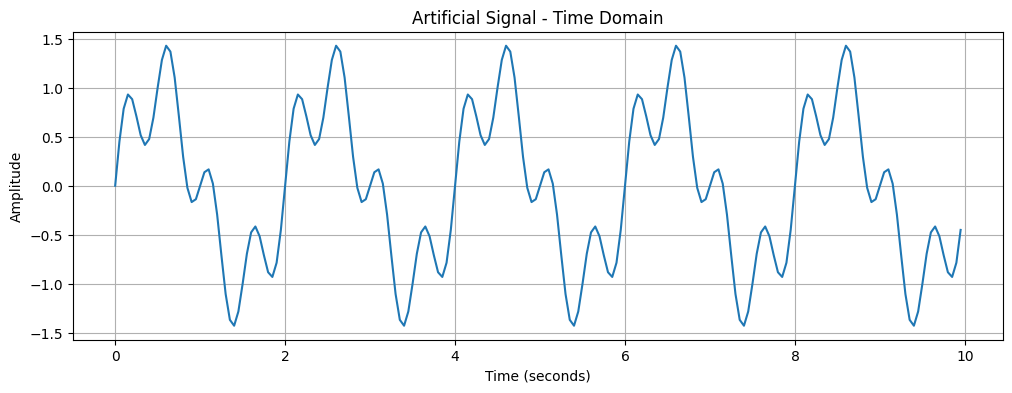

In [4]:

# Generate an artificial signal

fs_demo = 20

duration = 10

t = np.arange(0, duration, 1/fs_demo)

demo_signal = (
    np.sin(2 * np.pi * 0.5 * t)
    +
    0.5 * np.sin(2 * np.pi * 2 * t)
)

# Plot time-domain signal

plt.figure(figsize=(12, 4))

plt.plot(t, demo_signal)

plt.title("Artificial Signal - Time Domain")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.grid()
plt.show()


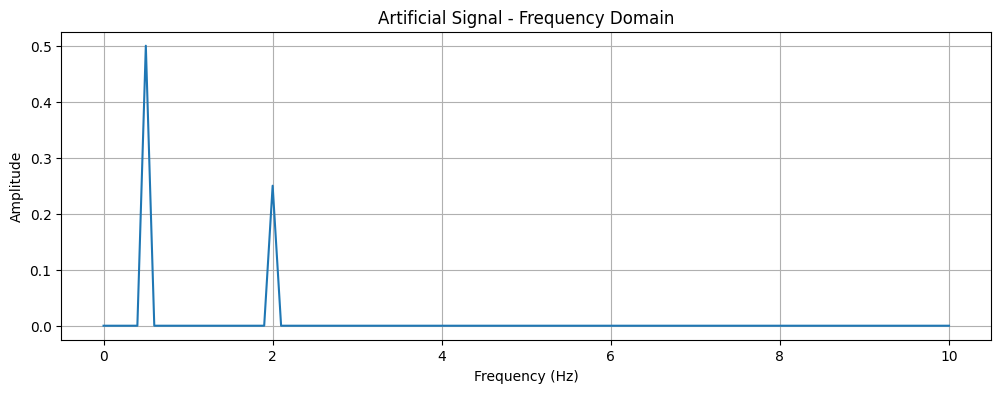

In [5]:
# Calculate FFT

N = len(demo_signal)

fft_values = np.fft.rfft(demo_signal)

frequencies = np.fft.rfftfreq(
    N,
    d=1/fs_demo
)

amplitude = np.abs(fft_values) / N

# Plot frequency spectrum

plt.figure(figsize=(12, 4))

plt.plot(frequencies, amplitude)

plt.title("Artificial Signal - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")

plt.grid()
plt.show()

In [6]:

# Calculate PSD using Welch method

frequencies, psd = welch(
    clean_signal,
    fs=fs,
    window="hann",
    nperseg=2048,
    noverlap=1024,
    scaling="density"
)

print("PSD calculation completed!")

print("Number of frequency points:", len(frequencies))

print("Frequency resolution:", frequencies[1] - frequencies[0], "Hz")


PSD calculation completed!
Number of frequency points: 1025
Frequency resolution: 0.009765625 Hz


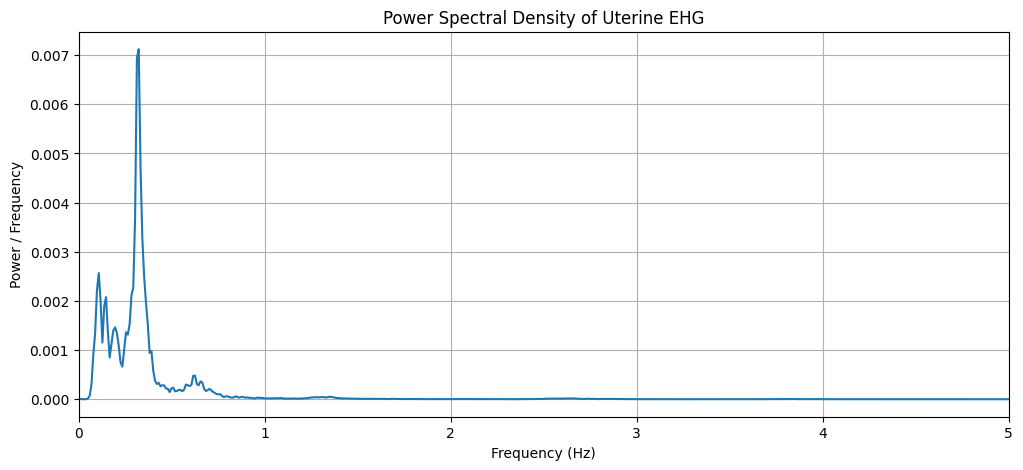

In [7]:

# Plot PSD

plt.figure(figsize=(12, 5))

plt.plot(frequencies, psd)

plt.xlim(0, 5)

plt.title("Power Spectral Density of Uterine EHG")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power / Frequency")

plt.grid(True)

plt.show()


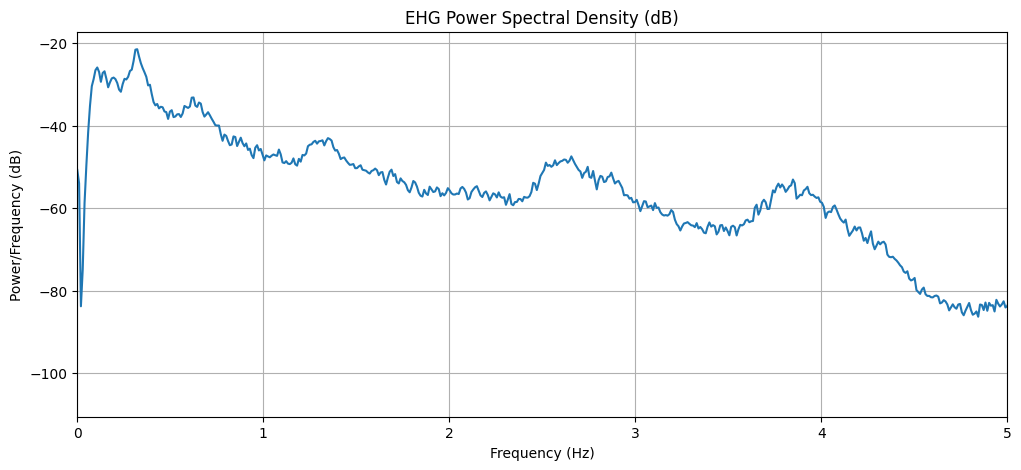

In [8]:

# PSD in decibels

psd_db = 10 * np.log10(
    np.maximum(psd, np.finfo(float).tiny)
)

plt.figure(figsize=(12, 5))

plt.plot(frequencies, psd_db)

plt.xlim(0, 5)

plt.title("EHG Power Spectral Density (dB)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power/Frequency (dB)")

plt.grid(True)

plt.show()


In [9]:

# Select frequency band

low_freq = 0.08
high_freq = 4.0

band_mask = (
    (frequencies >= low_freq) &
    (frequencies <= high_freq)
)

band_frequencies = frequencies[band_mask]
band_psd = psd[band_mask]

print("Selected frequency range:")
print(band_frequencies[0], "to", band_frequencies[-1], "Hz")


Selected frequency range:
0.087890625 to 3.994140625 Hz


In [10]:

# Total band power

total_power = np.trapezoid(
    band_psd,
    band_frequencies
)

print("Total Band Power:", total_power)


Total Band Power: 0.0007644060003747406


In [11]:

# Mean frequency

mean_frequency = np.sum(
    band_frequencies * band_psd
) / np.sum(band_psd)

print("Mean Frequency:", mean_frequency, "Hz")


Mean Frequency: 0.34263014983388657 Hz


In [12]:

# Median frequency

cumulative_power = np.cumsum(band_psd)

median_index = np.searchsorted(
    cumulative_power,
    cumulative_power[-1] / 2
)

median_frequency = band_frequencies[
    median_index
]

print("Median Frequency:", median_frequency, "Hz")


Median Frequency: 0.3125 Hz


In [13]:

# Peak frequency

peak_index = np.argmax(band_psd)

peak_frequency = band_frequencies[
    peak_index
]

print("Peak Frequency:", peak_frequency, "Hz")


Peak Frequency: 0.322265625 Hz


In [14]:

# Create frequency-domain feature dictionary

frequency_features = {

    "Total_Band_Power": total_power,

    "Mean_Frequency": mean_frequency,

    "Median_Frequency": median_frequency,

    "Peak_Frequency": peak_frequency

}

# Convert to DataFrame

frequency_df = pd.DataFrame(
    [frequency_features]
)

display(frequency_df)


,Total_Band_Power,Mean_Frequency,Median_Frequency,Peak_Frequency
0,0.000764,0.34263,0.3125,0.322266


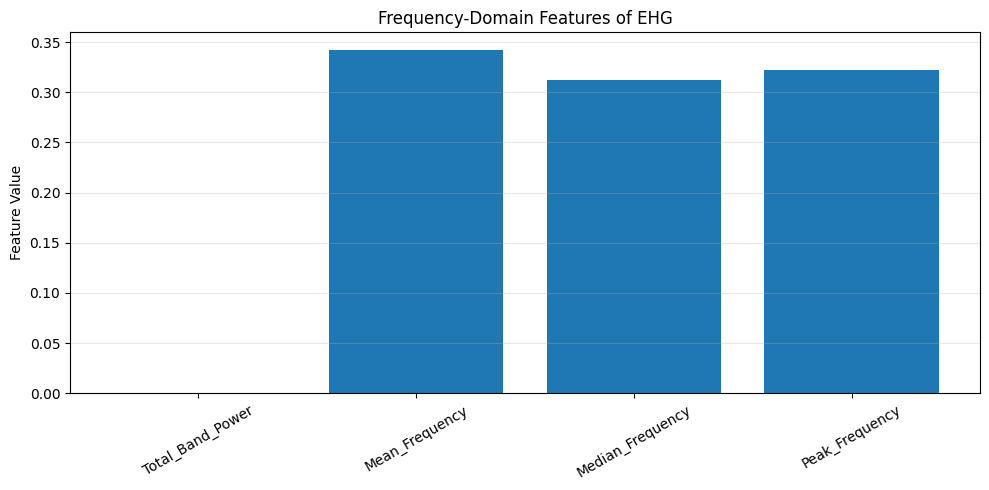

In [15]:

# Visualize frequency-domain features

plt.figure(figsize=(10, 5))

plt.bar(
    frequency_features.keys(),
    frequency_features.values()
)

plt.title("Frequency-Domain Features of EHG")
plt.ylabel("Feature Value")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
